# Una superficie de bordo y espaciamiento: dos palancas a la vez en tres tipos de brazo

**Nivel 2: El método en la práctica** · Requiere: 06-design-response/01-moving-one-lever-at-a-time · Tiempo de lectura: unos 30 minutos

## Objetivos

Cambiar una palanca a la vez esconde cómo interactúan dos de ellas. El grupo Diseño de la aplicación web muestra una superficie de respuesta sobre el bordo y el espaciamiento, con cada modelo recalculado sobre el diseño que usted cambia. Este cuaderno construye esa superficie para un tiro y lee qué dice su forma de cada brazo.

Al terminar habrá:

- barrido el bordo y el espaciamiento de un tiro de Akdaglar en una grilla de 7 por 7, con el propio `apply_variant` del producto;
- predicho toda la grilla con la ecuación clásica, la regresión publicada y un brazo aprendido, y dibujado las tres superficies;
- verificado el exponente que la ecuación clásica implica para el volumen de roca, y contado cuántos valores distintos puede producir un modelo de árboles en la grilla.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| Los tiros de Akdaglar | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| El mecanismo de variantes y la guarda de diseño degenerado | este repositorio (MIT) | la licencia propia del producto | `data-pipeline/pipeline/model/blasts.py`, importado por ruta |
| El artefacto del caso, para el tiro representativo | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-akdaglar/case.json` |

Los factores del barrido (0,7 a 1,3) son entradas de este cuaderno: un rango alrededor del diseño base que se mantiene dentro del envolvente del corpus, no datos.

## Método

Un punto de la grilla es un tiro con dos multiplicadores aplicados: uno sobre la razón bordo-diámetro (que escala juntas todas las longitudes del patrón, pues el diámetro es fijo) y uno sobre la razón espaciamiento-bordo (que estira solo el espaciamiento). `apply_variant` aplica un multiplicador, así que dos llamadas aplican dos. Cada diseño perturbado se revisa con `is_degenerate` y luego se predice.

Para la ecuación clásica la superficie tiene una forma conocida. Con factor de carga fijo `V/Q` es constante, así que el tamaño medio varía solo por `Q^(1/6)`, y `Q` es el factor de carga por el volumen de roca `V = B * S * H`. La pendiente del log del tamaño medio contra el log del volumen debe ser por tanto 1/6 (Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013). La celda lo verifica en la grilla.

La regresión es una ley de potencia de las siete razones (Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957), suave por construcción. Un conjunto de árboles como gradient boosting (Sui et al. 2025, https://doi.org/10.3390/app15031254) es constante por tramos: solo puede devolver los valores que guardan sus hojas.

### Paso 1: el diseño base y la grilla

La celda toma el tiro representativo del caso Akdaglar (el primero con geometría), construye los tres brazos como en el cuaderno anterior, y tiende una grilla de 7 por 7 de multiplicadores sobre la razón de bordo y la de espaciamiento.

In [2]:
# Importaciones, el tiro representativo, los tres brazos y la grilla de multiplicadores
import dataclasses
import json
import sys
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.cases.fragmenta_cases import Variant
from pipeline.model.blasts import apply_variant, is_degenerate

DERIVED = Path("../../../data/derived")
artifact = json.loads((DERIVED / "real-akdaglar" / "case.json").read_text(encoding="utf-8"))
train = bf.load_training_corpus()
base = next(b for b in train if b.blast_id == artifact["representative_blast_id"])
arms = {
    "kuznetsov": bf.Kuznetsov(dict(bf.SITE_ROCK_FACTOR)),
    "published-regression": bf.PublishedRegression(),
    "xgboost": bf.default_arms()["xgboost"]().fit([b for b in train if b.site != base.site]),
}
factors = np.linspace(0.7, 1.3, 7)
print("diseño base:", base.blast_id, "|", base.site, "| B/D", base.B_over_D, "| S/B", base.S_over_B)
print("multiplicadores:", [round(float(f), 2) for f in factors])

diseño base: Ad1 | Akdaglar | B/D 28.09 | S/B 1.2
multiplicadores: [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]


### Paso 2: predecir la grilla

Para cada par de multiplicadores la celda perturba el tiro base dos veces, comprueba que sigue siendo un tiro, reconstruye su volumen y lo predice con cada brazo. Un punto degenerado se dejaría en blanco; no se espera ninguno dentro de este rango.

In [3]:
# Predecir cada punto de la grilla con cada brazo y registrar el volumen de roca del diseño perturbado
surface = {name: np.full((7, 7), np.nan) for name in arms}
volume = np.full((7, 7), np.nan)
for i, burden_factor in enumerate(factors):
    for j, spacing_factor in enumerate(factors):
        step1 = apply_variant(base, Variant("grid-b", "", "", "B_over_D", float(burden_factor)))
        point = apply_variant(step1, Variant("grid-s", "", "", "S_over_B", float(spacing_factor)))
        if is_degenerate(point) is not None:
            continue
        volume[i, j] = bf.reconstruct_pattern(point).rock_volume_m3
        for name, arm in arms.items():
            prediction = arm.predict_one(point)
            if prediction.x50_m is not None:
                surface[name][i, j] = prediction.x50_m
print("puntos de la grilla predichos por cada brazo:", int(np.isfinite(np.stack(list(surface.values()))).all(axis=0).sum()), "de 49")
print(f"{'brazo':<22}{'mín (m)':>10}{'máx (m)':>10}{'valores distintos':>20}")
for name, grid in surface.items():
    print(f"{name:<22}{np.nanmin(grid):>10.4f}{np.nanmax(grid):>10.4f}{len(np.unique(np.round(grid, 9))):>20}")

puntos de la grilla predichos por cada brazo: 49 de 49
brazo                    mín (m)   máx (m)   valores distintos
kuznetsov                 0.1705    0.2576                  49
published-regression      0.1341    0.2450                  49
xgboost                   0.2185    0.2870                  17


### Paso 3: el exponente de la ecuación clásica

La celda regresa el log de la predicción clásica sobre el log del volumen de roca en los 49 puntos. Con el factor de carga fijo, la ecuación implica una pendiente de exactamente 1/6.

In [4]:
# Pendiente log-log del tamaño medio clásico contra el volumen de roca en la grilla
slope = np.polyfit(np.log(volume.ravel()), np.log(surface["kuznetsov"].ravel()), 1)[0]
print(f"pendiente de ln x50 contra ln V = {slope:.6f} | 1/6 = {1 / 6:.6f}")

pendiente de ln x50 contra ln V = 0.166667 | 1/6 = 0.166667


### Paso 4: las tres superficies

La celda dibuja las superficies lado a lado con una escala de color compartida, de modo que las diferencias de nivel y de forma sean legibles. Los ejes son los multiplicadores; la celda central es el diseño base.

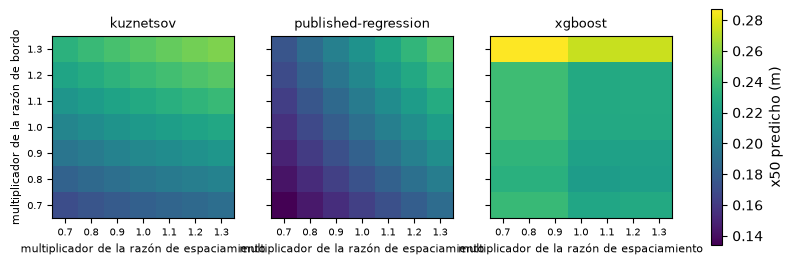

In [5]:
# Las tres superficies de respuesta sobre una escala de color compartida
low = min(np.nanmin(g) for g in surface.values())
high = max(np.nanmax(g) for g in surface.values())
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
for ax, (name, grid) in zip(axes, surface.items()):
    image = ax.imshow(grid, origin="lower", vmin=low, vmax=high, cmap="viridis")
    ax.set_xticks(range(7), [f"{f:.1f}" for f in factors], fontsize=7)
    ax.set_yticks(range(7), [f"{f:.1f}" for f in factors], fontsize=7)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("multiplicador de la razón de espaciamiento", fontsize=8)
axes[0].set_ylabel("multiplicador de la razón de bordo", fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.85, label="x50 predicho (m)")
plt.show()

## Resultados

**La superficie clásica es exactamente lo que dice la ecuación.** La pendiente del log del tamaño medio contra el log del volumen es 1/6 a seis dígitos, así que la superficie es una única potencia suave del volumen: sube con el bordo y con el espaciamiento, y las dos palancas se compensan a lo largo de líneas de volumen constante. Nada en ella se aprende.

**La regresión también es suave, con otros exponentes.** Toma un valor distinto en cada uno de los 49 puntos, con los exponentes que ajustaron Hudaverdi et al., y cubre un rango de tamaños algo distinto del de la superficie clásica (vea la tabla de arriba).

**La superficie aprendida es una escalera.** Gradient boosting devuelve solo los valores que guardan sus hojas, así que los 49 puntos de la grilla colapsan en muchos menos valores distintos que los que producen los otros dos brazos (el conteo está en la tabla de arriba), y diseños vecinos comparten una predicción. No es un error; es lo que un conjunto de árboles sobre 85 filas puede decir. También significa que la respuesta del brazo aprendido a un cambio de diseño es mucho más gruesa de lo que sugiere su puntaje.

**Qué no muestra esto.** Las tres superficies son respuestas de modelo sobre un tiro de un sitio. Cubren rangos de tamaño distintos, y ningún conjunto de datos registra el efecto de cambiar una palanca en un rajo dado, así que ninguna puede llamarse la correcta. La superficie responde "qué dice este modelo", no "cómo se verá la pila".

## Resumen

- Dos llamadas a `apply_variant` hacen un punto de la grilla; `is_degenerate` lo protege; todos los brazos lo predicen.
- La superficie clásica sigue la ecuación (pendiente 1/6 contra el log del volumen), la regresión es una ley de potencia suave con otros exponentes, y un conjunto de árboles es una escalera.
- Las superficies difieren entre sí más de lo que cualquier palanca mueve a cualquiera, y ninguna está validada contra una respuesta observada.
- Siguiente: el cuaderno 03 muestra cómo se sirven en vivo los brazos aprendidos desde un documento portable (nivel 4).

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (la regresión publicada)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (la ecuación clásica, cuya dependencia del volumen se verifica aquí)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (gradient boosting)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/